<a href="https://colab.research.google.com/github/Subhajit-Dey45/HandWritten-digit-and-character/blob/main/handwrittendigitclassification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/digit-recognizer/train.csv
/kaggle/input/digit-recognizer/test.csv


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.model_selection import train_test_split

2024-04-14 12:22:04.450492: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-04-14 12:22:04.450634: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-04-14 12:22:04.583036: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [ ]:
data=pd.read_csv("/kaggle/input/digit-recognizer/train.csv")
test_data=pd.read_csv("/kaggle/input/digit-recognizer/test.csv")

In [ ]:
data

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41995,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41996,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41997,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41998,6,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
test_data

,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27995,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
27996,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
27997,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
27998,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
x=data.iloc[:,1:].values  # .values is to convert dataframe to numpy array

In [ ]:
x

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

In [ ]:
y=data.iloc[:,0].values

In [ ]:
y

array([1, 0, 1, ..., 7, 6, 9])

In [ ]:
print(x.shape)
print(y.shape)

(42000, 784)
(42000,)


In [ ]:
x=x/255 #scaling the values from 0-1

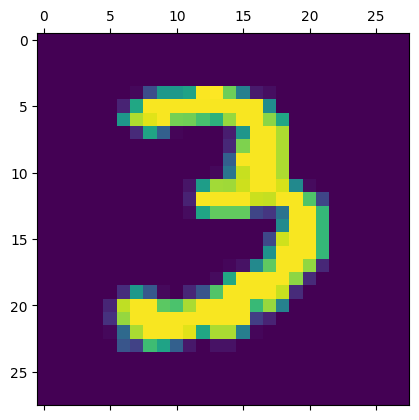

In [ ]:
plt.matshow(x[9].reshape(28,28))  # converting from 1d to 2d matrix then getting plot

In [ ]:
# Now we alread have a 1-D matrix of dataset
# We'll move to keras part

In [ ]:
# split in training and testing data

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.3,random_state=20,stratify=y)

In [ ]:
# 10 neurons, sigmoid activation function
# we can add more hidden layers here
# only first layer need input_shape=( )
model=keras.Sequential([
    keras.layers.Dense(10,input_shape=(784,), activation='sigmoid')
])
model.compile(
    optimizer='adam',  # allow to train efficiently (adam or SGD)
    loss='sparse_categorical_crossentropy',   # loss function
    metrics=['accuracy']   # metirc to check
)

/opt/conda/lib/python3.10/site-packages/keras/src/layers/core/dense.py:88: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.fit(x_train,y_train,epochs=5)   # epochs = 5 means--> we go through the sample 5 times

Epoch 1/5
919/919 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.7524 - loss: 0.9254
Epoch 2/5
919/919 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9029 - loss: 0.3583
Epoch 3/5
919/919 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9095 - loss: 0.3149
Epoch 4/5
919/919 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9209 - loss: 0.2818
Epoch 5/5
919/919 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9218 - loss: 0.2820


In [ ]:
model.evaluate(x_test,y_test)
# will show (loss,accuracy)

394/394 ━━━━━━━━━━━━━━━━━━━━ 0s 929us/step - accuracy: 0.9187 - loss: 0.2850


[0.2791845500469208, 0.9223015904426575]

In [ ]:
y_pred=model.predict(x_test)

394/394 ━━━━━━━━━━━━━━━━━━━━ 0s 968us/step


In [ ]:
y_pred[0] # will show 10 values (for every number 0-9) ---> maximum value jiski hogi voh number hoga
# here it is 7 (value: 9.999939)

array([5.0728465e-04, 3.9543139e-08, 4.3060561e-03, 9.5165235e-01,
       8.3552243e-04, 1.3586288e-04, 1.7134297e-06, 9.9999666e-01,
       4.2001583e-02, 4.1077834e-02], dtype=float32)

In [ ]:
np.argmax(y_pred[0])  # Confirmation

7

In [ ]:
# Finding argmax for every y_pred
y_pred_labels=[np.argmax(i) for i in y_pred]
y_pred_labels[:5] # first 5

[7, 2, 8, 3, 2]

In [ ]:
# Confusion matrix
cm=tf.math.confusion_matrix(labels=y_test, predictions=y_pred_labels)
cm

<tf.Tensor: shape=(10, 10), dtype=int32, numpy=
array([[1201,    0,    6,    4,    2,    8,    9,    2,    8,    0],
       [   0, 1362,    5,   10,    1,    8,    1,    2,   15,    1],
       [   6,   13, 1115,   33,   14,    4,   14,   15,   34,    5],
       [   4,    4,   22, 1207,    0,   32,    4,   13,   11,    8],
       [   4,    4,   10,    3, 1113,    2,   14,    3,    9,   60],
       [  12,    2,    4,   68,   17,  949,   25,    6,   42,   14],
       [  13,    3,    5,    1,    7,   11, 1197,    0,    4,    0],
       [   6,    5,   10,    7,   10,    0,    0, 1231,    1,   50],
       [  10,   14,    5,   46,    6,   18,   14,    5, 1082,   19],
       [   2,    5,    4,   18,   19,    7,    0,   25,   12, 1164]],
      dtype=int32)>

Text(70.72222222222221, 0.5, 'Truth')

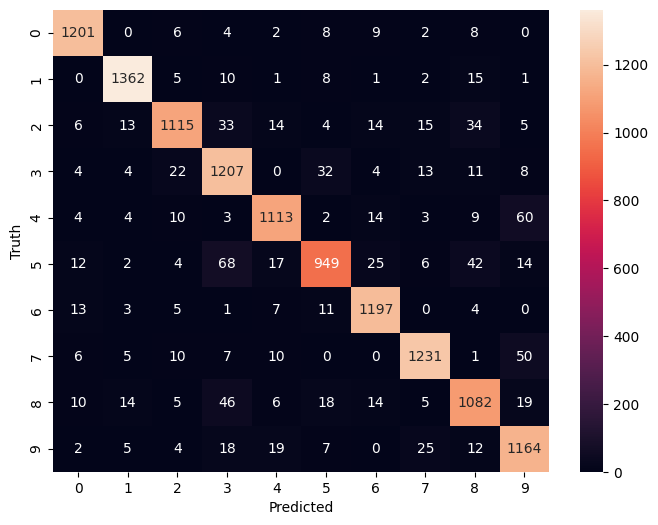

In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(cm,annot=True,fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Truth")

# values in black region are errors --->

In [ ]:
## Let's add more hidden layers and try



model1=keras.Sequential([
    keras.layers.Dense(100,input_shape=(784,), activation='relu'),    # hidden layer
    keras.layers.Dense(10, activation='sigmoid')
])
model1.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model1.fit(x_train,y_train,epochs=5)

/opt/conda/lib/python3.10/site-packages/keras/src/layers/core/dense.py:88: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
919/919 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8295 - loss: 0.5962
Epoch 2/5
919/919 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9468 - loss: 0.1826
Epoch 3/5
919/919 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9639 - loss: 0.1212
Epoch 4/5
919/919 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9731 - loss: 0.0903
Epoch 5/5
919/919 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9801 - loss: 0.0682


In [ ]:
model1.evaluate(x_test,y_test)      #--- will get more accuracy less loss
# will show (loss,accuracy)

394/394 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9654 - loss: 0.1106


[0.10791008174419403, 0.9669841527938843]

394/394 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


Text(70.72222222222221, 0.5, 'Truth')

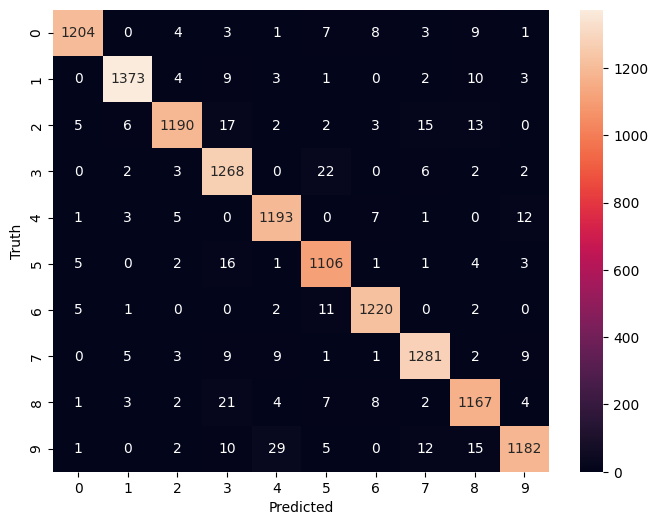

In [ ]:
y_pred1=model1.predict(x_test)
y_pred_labels1=[np.argmax(i) for i in y_pred1]
cm1=tf.math.confusion_matrix(labels=y_test, predictions=y_pred_labels1)

plt.figure(figsize=(8,6))
sns.heatmap(cm1,annot=True,fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Truth")